# FedEx Logistics Performance Analysis
## Exploratory Data Analysis (EDA) Capstone Project

**Domain:** Supply Chain & Logistics  
**Environment:** Google Colab  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, Plotly, SciPy

---

### Project Summary
This project performs an end-to-end exploratory data analysis of FedEx logistics / supply-chain shipment records. The analysis focuses on shipment mode usage, delivery reliability, freight cost, geographic concentration, vendor activity, and operational bottlenecks. The objective is to convert raw logistics records into clear and actionable business recommendations that can support cost control and more reliable deliveries.

**GitHub Repository:** `ADD_PUBLIC_GITHUB_REPOSITORY_LINK_BEFORE_SUBMISSION`

> **Submission note:** Replace the GitHub placeholder above with the final public repository link before submitting the project.

# 1. Problem Statement

FedEx Logistics manages shipments across multiple countries, vendors, products, and transportation modes. The logistics dataset contains operational information such as purchase order references, shipment modes, vendor INCO terms, scheduled and actual delivery dates, product details, shipment weight, freight cost, and line-item value.

The business needs a structured analysis to answer the following questions:

1. Which shipment modes are used most frequently and how do they perform?
2. Where are delivery delays concentrated?
3. Which countries and shipment methods drive the highest freight cost?
4. How strongly are shipment weight and freight cost related?
5. Does fulfillment through an RDC show a different delay pattern from Direct Drop?
6. Which vendors and product groups dominate shipment activity?
7. What operational actions can improve delivery reliability and cost efficiency?

# 2. Business Context

Efficient logistics management is essential for global distribution because late shipments can reduce customer satisfaction and operational reliability, while excessive freight expense can reduce margins. A data-driven review of delivery dates, transportation modes, country-level activity, vendors, weights, and freight cost can help stakeholders identify bottlenecks and prioritize improvement opportunities.

### Business Objectives
- Improve delivery reliability and reduce avoidable delays.
- Understand the cost profile of different shipment modes.
- Identify countries and routes associated with high logistics spending.
- Compare Direct Drop and RDC-based fulfillment performance.
- Quantify the relationship between shipment weight and freight cost.
- Provide practical recommendations for operations, procurement, and finance teams.

# 3. Dataset Understanding

The project uses the **SCMS Delivery History Dataset**, a logistics dataset containing shipment, delivery, vendor, product, cost, and route-related information.

For reproducibility, the notebook loads a public mirror of the SCMS Delivery History CSV corresponding to this FedEx logistics project. The dataset contains **10,324 records and 33 columns**.

Important variables include:
- `Country` — destination country.
- `Fulfill Via` — fulfillment channel such as Direct Drop or From RDC.
- `Vendor INCO Term` — commercial delivery terms.
- `Shipment Mode` — Air, Truck, Ocean, Air Charter, etc.
- `Scheduled Delivery Date` — planned delivery date.
- `Delivered to Client Date` — actual delivery date.
- `Product Group` — product category.
- `Vendor` — supplier / distribution source.
- `Line Item Quantity` and `Line Item Value` — shipment item volume and value.
- `Weight (Kilograms)` — shipment weight where numeric weight is available.
- `Freight Cost (USD)` — freight cost where a separate numeric cost is available.
- `Line Item Insurance (USD)` — item-level insurance amount.

# 4. Import Libraries

The following libraries are used:
- **Pandas** for data manipulation and aggregation.
- **NumPy** for numerical operations.
- **Matplotlib** and **Seaborn** for static visualizations.
- **Plotly** for an interactive visualization.
- **SciPy** for statistical analysis.

In [ ]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from scipy.stats import spearmanr

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

print('Libraries imported successfully.')

Libraries imported successfully.


# 5. Data Loading

The raw CSV is loaded directly from a public GitHub mirror so the notebook remains reproducible in Google Colab without requiring a manual file upload.

In [ ]:
DATA_URL = 'https://raw.githubusercontent.com/Franklin251198/Fedex-logistics-performance-analysis/main/SCMS_Delivery_History_Dataset.csv'

df = pd.read_csv(DATA_URL)
print('Dataset loaded successfully.')
print('Shape:', df.shape)
df.head()

Dataset loaded successfully.
Shape: (10324, 33)


,ID,Project Code,PQ #,PO / SO #,ASN/DN #,Country,Managed By,Fulfill Via,Vendor INCO Term,Shipment Mode,PQ First Sent to Client Date,PO Sent to Vendor Date,Scheduled Delivery Date,Delivered to Client Date,Delivery Recorded Date,Product Group,Sub Classification,Vendor,Item Description,Molecule/Test Type,Brand,Dosage,Dosage Form,Unit of Measure (Per Pack),Line Item Quantity,Line Item Value,Pack Price,Unit Price,Manufacturing Site,First Line Designation,Weight (Kilograms),Freight Cost (USD),Line Item Insurance (USD)
0,1,100-CI-T01,Pre-PQ Process,SCMS-4,ASN-8,Côte d'Ivoire,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,2-Jun-06,2-Jun-06,2-Jun-06,HRDT,HIV test,RANBAXY Fine Chemicals LTD.,"HIV, Reveal G3 Rapid HIV-1 Antibody Test, 30 T...","HIV, Reveal G3 Rapid HIV-1 Antibody Test",Reveal,NaN,Test kit,30,19,551.00,29.00,0.97,Ranbaxy Fine Chemicals LTD,Yes,13,780.34,NaN
1,3,108-VN-T01,Pre-PQ Process,SCMS-13,ASN-85,Vietnam,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,14-Nov-06,14-Nov-06,14-Nov-06,ARV,Pediatric,Aurobindo Pharma Limited,"Nevirapine 10mg/ml, oral suspension, Bottle, 2...",Nevirapine,Generic,10mg/ml,Oral suspension,240,1000,"6,200.00",6.20,0.03,"Aurobindo Unit III, India",Yes,358,4521.5,NaN
2,4,100-CI-T01,Pre-PQ Process,SCMS-20,ASN-14,Côte d'Ivoire,PMO - US,Direct Drop,FCA,Air,Pre-PQ Process,Date Not Captured,27-Aug-06,27-Aug-06,27-Aug-06,HRDT,HIV test,Abbott GmbH & Co. KG,"HIV 1/2, Determine Complete HIV Kit, 100 Tests","HIV 1/2, Determine Complete HIV Kit",Determine,NaN,Test kit,100,500,"40,000.00",80.00,0.80,ABBVIE GmbH & Co.KG Wiesbaden,Yes,171,1653.78,NaN
3,15,108-VN-T01,Pre-PQ Process,SCMS-78,ASN-50,Vietnam,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,1-Sep-06,1-Sep-06,1-Sep-06,ARV,Adult,SUN PHARMACEUTICAL INDUSTRIES LTD (RANBAXY LAB...,"Lamivudine 150mg, tablets, 60 Tabs",Lamivudine,Generic,150mg,Tablet,60,31920,"127,360.80",3.99,0.07,"Ranbaxy, Paonta Shahib, India",Yes,1855,16007.06,NaN
4,16,108-VN-T01,Pre-PQ Process,SCMS-81,ASN-55,Vietnam,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,11-Aug-06,11-Aug-06,11-Aug-06,ARV,Adult,Aurobindo Pharma Limited,"Stavudine 30mg, capsules, 60 Caps",Stavudine,Generic,30mg,Capsule,60,38000,"121,600.00",3.20,0.05,"Aurobindo Unit III, India",Yes,7590,45450.08,NaN


# 6. Initial Data Exploration

Before cleaning, we inspect the structure, data types, descriptive statistics, missing values, and duplicate rows. This prevents us from making assumptions about the data before understanding its quality.

In [ ]:
print('Rows:', df.shape[0])
print('Columns:', df.shape[1])
print('\nColumn names:')
for i, col in enumerate(df.columns, start=1):
    print(f'{i:02d}. {col}')

Rows: 10324
Columns: 33

Column names:
01. ID
02. Project Code
03. PQ #
04. PO / SO #
05. ASN/DN #
06. Country
07. Managed By
08. Fulfill Via
09. Vendor INCO Term
10. Shipment Mode
11. PQ First Sent to Client Date
12. PO Sent to Vendor Date
13. Scheduled Delivery Date
14. Delivered to Client Date
15. Delivery Recorded Date
16. Product Group
17. Sub Classification
18. Vendor
19. Item Description
20. Molecule/Test Type
21. Brand
22. Dosage
23. Dosage Form
24. Unit of Measure (Per Pack)
25. Line Item Quantity
26. Line Item Value
27. Pack Price
28. Unit Price
29. Manufacturing Site
30. First Line Designation
31. Weight (Kilograms)
32. Freight Cost (USD)
33. Line Item Insurance (USD)


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10324 entries, 0 to 10323
Data columns (total 33 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   ID                            10324 non-null  int64  
 1   Project Code                  10324 non-null  object 
 2   PQ #                          10324 non-null  object 
 3   PO / SO #                     10324 non-null  object 
 4   ASN/DN #                      10324 non-null  object 
 5   Country                       10324 non-null  object 
 6   Managed By                    10324 non-null  object 
 7   Fulfill Via                   10324 non-null  object 
 8   Vendor INCO Term              10324 non-null  object 
 9   Shipment Mode                 9964 non-null   object 
 10  PQ First Sent to Client Date  10324 non-null  object 
 11  PO Sent to Vendor Date        10324 non-null  object 
 12  Scheduled Delivery Date       10324 non-null  object 
 13  D

In [ ]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID,"10,324.00",NaN,NaN,NaN,"51,098.97","31,944.33",1.00,"12,795.75","57,540.50","83,648.25","86,823.00"
Project Code,10324,142,116-ZA-T30,768,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PQ #,10324,1237,Pre-PQ Process,2681,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PO / SO #,10324,6233,SCMS-199289,67,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ASN/DN #,10324,7030,ASN-19166,54,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,10324,43,South Africa,1406,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Managed By,10324,4,PMO - US,10265,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fulfill Via,10324,2,From RDC,5404,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Vendor INCO Term,10324,8,N/A - From RDC,5404,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Shipment Mode,9964,4,Air,6113,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
quality_summary = pd.DataFrame({
    'Data Type': df.dtypes.astype(str),
    'Missing Values': df.isna().sum(),
    'Missing %': (df.isna().mean() * 100).round(2),
    'Unique Values': df.nunique(dropna=True)
}).sort_values('Missing %', ascending=False)

print('Exact duplicate rows:', df.duplicated().sum())
quality_summary

Exact duplicate rows: 0


,Data Type,Missing Values,Missing %,Unique Values
Dosage,object,1736,16.82,54
Shipment Mode,object,360,3.49,4
Line Item Insurance (USD),float64,287,2.78,6722
ID,int64,0,0.00,10324
Project Code,object,0,0.00,142
Country,object,0,0.00,43
Managed By,object,0,0.00,4
PO / SO #,object,0,0.00,6233
PQ #,object,0,0.00,1237
Vendor INCO Term,object,0,0.00,8


### Initial Data Quality Remarks

- The dataset contains **10,324 rows and 33 columns**.
- There are **no exact duplicate rows** in the raw dataset.
- Most fields do not contain conventional blank values; however, some operational numeric fields contain text such as `Weight Captured Separately`, `See DN-...`, `Freight Included in Commodity Cost`, or `Invoiced Separately`.
- `Line Item Insurance (USD)` contains some missing values.
- Date columns also contain operational labels such as `Date Not Captured`, `Pre-PQ Process`, and `N/A - From RDC`.

Therefore, the main cleaning task is not only checking `NaN`; it is also converting mixed text/numeric and mixed text/date columns safely.

# 7. Data Cleaning and Preparation

### Cleaning Strategy
1. Preserve the raw columns for traceability.
2. Convert key numeric fields with `errors='coerce'` so non-numeric operational labels become missing numeric values instead of causing errors.
3. Convert delivery-related date columns with `errors='coerce'`.
4. Keep high-value and heavy shipments because they may represent genuine operational cases; do not delete them simply because they are statistical outliers.
5. Create derived variables for delivery delay, delivery status, cost per kilogram, month, and year.

In [ ]:
# Work on a copy so the raw dataframe remains unchanged.
data = df.copy()

# Clean numeric columns that contain a mixture of numbers and text labels.
data['Weight_kg'] = pd.to_numeric(data['Weight (Kilograms)'], errors='coerce')
data['Freight_Cost_USD'] = pd.to_numeric(data['Freight Cost (USD)'], errors='coerce')
data['Insurance_USD'] = pd.to_numeric(data['Line Item Insurance (USD)'], errors='coerce')

# The following columns are already mostly numeric, but explicit conversion improves reliability.
for col in ['Line Item Quantity', 'Line Item Value', 'Pack Price', 'Unit Price']:
    data[col] = pd.to_numeric(data[col], errors='coerce')

numeric_conversion_summary = pd.DataFrame({
    'Valid numeric values': data[['Weight_kg', 'Freight_Cost_USD', 'Insurance_USD']].notna().sum(),
    'Missing after conversion': data[['Weight_kg', 'Freight_Cost_USD', 'Insurance_USD']].isna().sum()
})
numeric_conversion_summary

,Valid numeric values,Missing after conversion
Weight_kg,6372,3952
Freight_Cost_USD,6198,4126
Insurance_USD,10037,287


### Numeric Cleaning Rationale

A missing numeric value after conversion does **not automatically mean bad data**. For example, some freight records state that freight was included in the commodity cost, while some weight values were recorded separately. These are meaningful operational categories, but they cannot be used directly in arithmetic. For numerical analyses, only valid numeric observations are used, while the original text columns are retained for auditability.

In [ ]:
# Convert important date columns.
date_columns = [
    'PQ First Sent to Client Date',
    'PO Sent to Vendor Date',
    'Scheduled Delivery Date',
    'Delivered to Client Date',
    'Delivery Recorded Date'
]

for col in date_columns:
    # format='mixed' safely handles values such as 2-Jun-06 and 11/13/06 in the same column.
    data[col + '_dt'] = pd.to_datetime(data[col], errors='coerce', format='mixed')

pd.DataFrame({
    'Valid Dates': [data[c + '_dt'].notna().sum() for c in date_columns],
    'Unparsed / Operational Labels': [data[c + '_dt'].isna().sum() for c in date_columns]
}, index=date_columns)

,Valid Dates,Unparsed / Operational Labels
PQ First Sent to Client Date,7643,2681
PO Sent to Vendor Date,4592,5732
Scheduled Delivery Date,10324,0
Delivered to Client Date,10324,0
Delivery Recorded Date,10324,0


In [ ]:
#-----------------------------------------------------------------------------------------
# Feature engineering for delivery performance.
data['Delivery_Delay_Days'] = (
    data['Delivered to Client Date_dt'] - data['Scheduled Delivery Date_dt']
).dt.days

data['Delivery_Status'] = np.where(
    data['Delivery_Delay_Days'].isna(),
    'Unknown',
    np.where(data['Delivery_Delay_Days'] > 0, 'Delayed', 'On Time/Early')
)

# Freight cost per kg is meaningful only when both values are valid and weight is positive.
data['Cost_per_Kg'] = np.where(
    (data['Weight_kg'] > 0) & data['Freight_Cost_USD'].notna(),
    data['Freight_Cost_USD'] / data['Weight_kg'],
    np.nan
)

data['Delivery_Year'] = data['Delivered to Client Date_dt'].dt.year
data['Delivery_Month'] = data['Delivered to Client Date_dt'].dt.to_period('M').astype(str)

data[['Delivery_Delay_Days', 'Delivery_Status', 'Cost_per_Kg', 'Delivery_Year', 'Delivery_Month']].head()

,Delivery_Delay_Days,Delivery_Status,Cost_per_Kg,Delivery_Year,Delivery_Month
0,0,On Time/Early,60.03,2006,2006-06
1,0,On Time/Early,12.63,2006,2006-11
2,0,On Time/Early,9.67,2006,2006-08
3,0,On Time/Early,8.63,2006,2006-09
4,0,On Time/Early,5.99,2006,2006-08


# 8. Outlier Assessment

Logistics data naturally contains very large orders, unusually heavy shipments, and expensive emergency shipments. Removing all statistical outliers would risk deleting genuine business events. Therefore:

- We identify outliers using the IQR rule.
- We **retain** the original observations for business analysis.
- We use log scales or filtered visual ranges when needed so extreme values do not hide the overall pattern.

In [ ]:
def iqr_outlier_summary(series):
    s = series.dropna()
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outliers = s[(s < lower) | (s > upper)]
    return pd.Series({
        'Q1': q1,
        'Q3': q3,
        'IQR': iqr,
        'Lower Bound': lower,
        'Upper Bound': upper,
        'Outlier Count': len(outliers),
        'Outlier %': round(len(outliers) / len(s) * 100, 2)
    })

outlier_table = pd.DataFrame({
    'Weight_kg': iqr_outlier_summary(data['Weight_kg']),
    'Freight_Cost_USD': iqr_outlier_summary(data['Freight_Cost_USD']),
    'Line Item Value': iqr_outlier_summary(data['Line Item Value'])
}).T
outlier_table

,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier %
Weight_kg,206.75,"3,334.00","3,127.25","-4,484.12","8,024.88",623.00,9.78
Freight_Cost_USD,"2,131.12","14,406.57","12,275.45","-16,282.06","32,819.75",388.00,6.26
Line Item Value,"4,314.59","166,447.14","162,132.55","-238,884.23","409,645.96","1,127.00",10.92


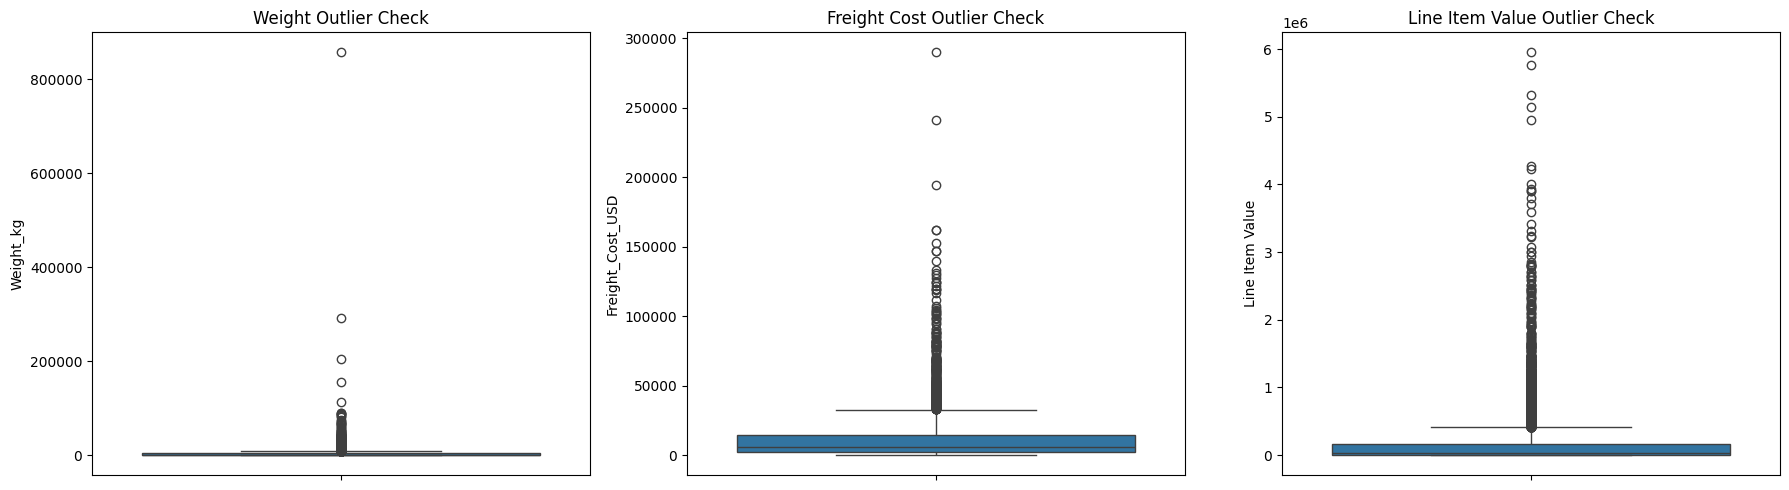

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(y=data['Weight_kg'], ax=axes[0])
axes[0].set_title('Weight Outlier Check')

sns.boxplot(y=data['Freight_Cost_USD'], ax=axes[1])
axes[1].set_title('Freight Cost Outlier Check')

sns.boxplot(y=data['Line Item Value'], ax=axes[2])
axes[2].set_title('Line Item Value Outlier Check')

plt.tight_layout()
plt.show()

### Outlier Remark
The boxplots are expected to show substantial right-tail outliers. In a global logistics dataset this can represent genuine high-volume or urgent shipments, so the project does not delete them blindly. This preserves operational reality while later charts use averages, medians, grouped metrics, or log scales for readability.

# 9. Hypotheses / Assumptions

Before visualization, the following business hypotheses are listed:

1. **H1:** Shipment mode is associated with delivery reliability; faster modes should generally show lower delay rates.
2. **H2:** Heavier shipments should generally have higher freight cost.
3. **H3:** Freight cost is concentrated in a small number of destination countries.
4. **H4:** Fulfillment through an RDC may show a different delay pattern from Direct Drop because it introduces an additional handling stage.
5. **H5:** Air-based transportation is expected to be used more frequently than Ocean transport for time-sensitive healthcare products.

These are working hypotheses, not conclusions. The following EDA tests them against the observed data.

# 10. KPI Overview

The KPI block gives stakeholders a quick summary before detailed charts.

In [ ]:
total_shipments = len(data)
unique_countries = data['Country'].nunique()
unique_vendors = data['Vendor'].nunique()
total_line_value = data['Line Item Value'].sum()
total_numeric_freight = data['Freight_Cost_USD'].sum()
delay_rate = data['Delivery_Status'].eq('Delayed').mean() * 100

kpi_table = pd.DataFrame({
    'KPI': [
        'Total Shipment Records',
        'Countries',
        'Vendors',
        'Total Line Item Value (USD)',
        'Total Numeric Freight Cost (USD)',
        'Delayed Shipment Rate (%)'
    ],
    'Value': [
        f'{total_shipments:,}',
        f'{unique_countries:,}',
        f'{unique_vendors:,}',
        f'${total_line_value:,.2f}',
        f'${total_numeric_freight:,.2f}',
        f'{delay_rate:.2f}%'
    ]
})
kpi_table

,KPI,Value
0,Total Shipment Records,"10,324"
1,Countries,43
2,Vendors,73
3,Total Line Item Value (USD),"$1,627,584,457.29"
4,Total Numeric Freight Cost (USD),"$68,817,849.41"
5,Delayed Shipment Rate (%),11.49%


## Analysis 1 — Shipment Mode Distribution

### Why this chart?
A count plot is appropriate for a categorical variable because it directly shows the volume handled by each transportation mode.

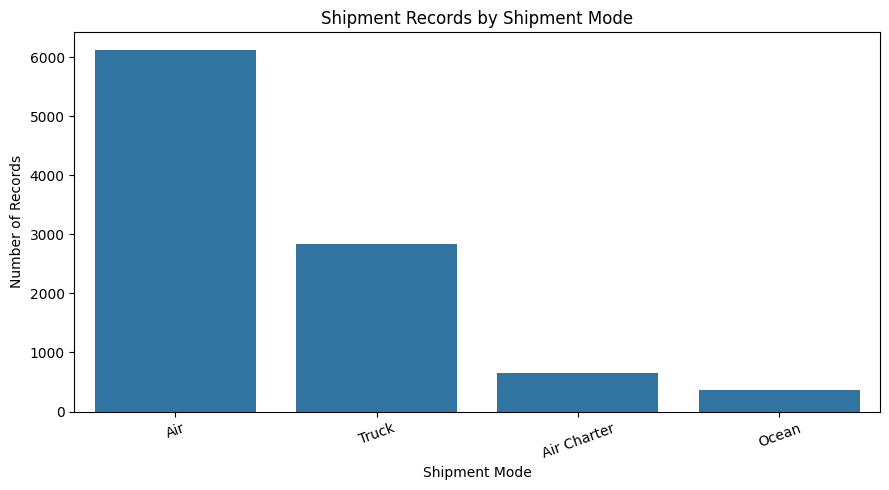

,Shipment Count
Shipment Mode,
Air,6113
Truck,2830
Air Charter,650
Ocean,371


In [ ]:
#------------------------------------------------------------------------------------------
shipment_counts = data['Shipment Mode'].value_counts()

plt.figure(figsize=(9, 5))
sns.barplot(x=shipment_counts.index, y=shipment_counts.values)
plt.title('Shipment Records by Shipment Mode')
plt.xlabel('Shipment Mode')
plt.ylabel('Number of Records')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

shipment_counts.to_frame('Shipment Count')

### Remark / Insight
Air is the dominant shipment mode, with **6,113 records (about 59% of all shipments)**, followed by Truck. This supports the assumption that the supply chain relies heavily on faster transportation, which is reasonable for healthcare and pharmaceutical products. However, heavy dependence on air transport can increase logistics expenditure, so cost and urgency should be balanced when selecting modes.

## Analysis 2 — Top Destination Countries by Shipment Volume

### Why this chart?
A horizontal bar chart makes it easy to compare countries with long names and identify geographic concentration.

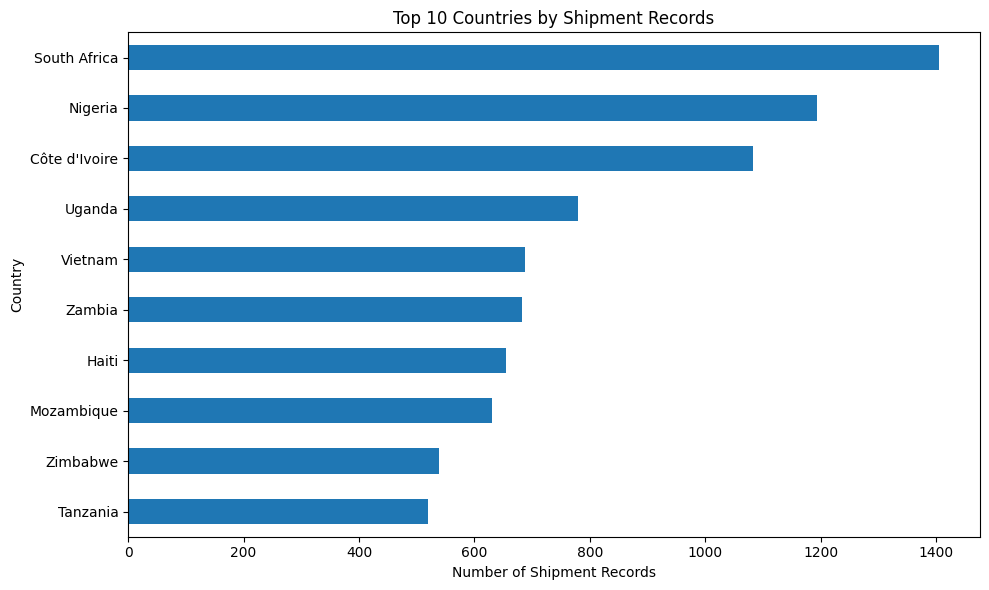

,Shipment Count
Country,
South Africa,1406
Nigeria,1194
Côte d'Ivoire,1083
Uganda,779
Vietnam,688
Zambia,683
Haiti,655
Mozambique,631
Zimbabwe,538


In [ ]:
#----------------------------------------------------------------------------------------------
top_countries = data['Country'].value_counts().head(10).sort_values()

plt.figure(figsize=(10, 6))
top_countries.plot(kind='barh')
plt.title('Top 10 Countries by Shipment Records')
plt.xlabel('Number of Shipment Records')
plt.ylabel('Country')
plt.tight_layout()
plt.show()

top_countries.sort_values(ascending=False).to_frame('Shipment Count')

### Remark / Insight
South Africa has the largest number of shipment records (**1,406**), followed by Nigeria and Côte d’Ivoire. This means operational monitoring should pay special attention to high-volume countries because even a small percentage improvement in these markets can affect a large number of shipments.

## Analysis 3 — Product Group Distribution

### Why this chart?
Understanding product mix helps interpret transportation choices. Healthcare products can have different urgency, storage, and service requirements.

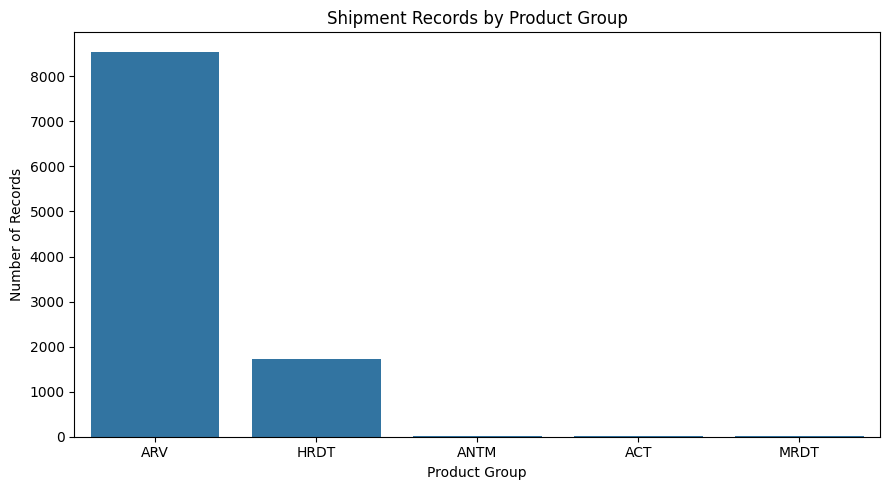

,Shipment Count
Product Group,
ARV,8550
HRDT,1728
ANTM,22
ACT,16
MRDT,8


In [ ]:
product_counts = data['Product Group'].value_counts()

plt.figure(figsize=(9, 5))
sns.barplot(x=product_counts.index, y=product_counts.values)
plt.title('Shipment Records by Product Group')
plt.xlabel('Product Group')
plt.ylabel('Number of Records')
plt.tight_layout()
plt.show()

product_counts.to_frame('Shipment Count')

### Remark / Insight
The dataset is strongly dominated by **ARV products (8,550 records, approximately 83%)**. This concentration explains why delivery reliability is especially important: the dataset primarily represents healthcare products where late delivery can have serious service consequences.

## Analysis 4 — Average Freight Cost by Shipment Mode

### Why this chart?
A grouped average highlights how the cost profile changes across transportation modes. Only records with a separately recorded numeric freight cost are included.

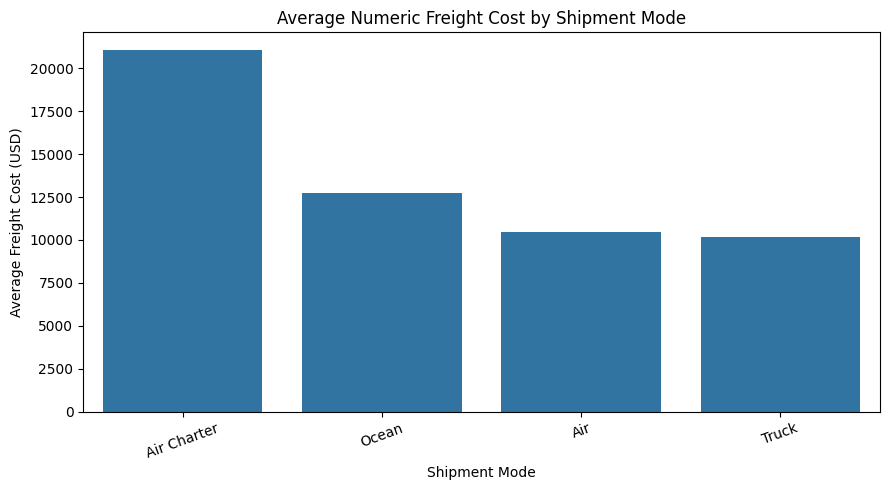

,count,mean,median
Shipment Mode,,,
Air Charter,424,"21,052.14","15,322.73"
Ocean,282,"12,733.08","9,520.98"
Air,4115,"10,458.96","4,764.16"
Truck,1166,"10,176.41","5,985.84"


In [ ]:
avg_freight_mode = (
    data.dropna(subset=['Freight_Cost_USD'])
        .groupby('Shipment Mode')['Freight_Cost_USD']
        .agg(['count', 'mean', 'median'])
        .sort_values('mean', ascending=False)
)

plt.figure(figsize=(9, 5))
sns.barplot(x=avg_freight_mode.index, y=avg_freight_mode['mean'])
plt.title('Average Numeric Freight Cost by Shipment Mode')
plt.xlabel('Shipment Mode')
plt.ylabel('Average Freight Cost (USD)')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

avg_freight_mode

### Remark / Insight
Among records with numeric freight cost, **Air Charter has the highest average freight cost (about $21.1K per record)**. Ocean is also high on average because it frequently carries heavy bulk shipments. The result shows that transportation cost cannot be judged by speed alone; shipment weight, urgency, route, and shipment size must be considered together.

**Business recommendation:** Reserve Air Charter for genuinely urgent cases and evaluate whether non-critical shipments can use standard Air, Truck, or Ocean depending on service requirements.

## Analysis 5 — Delivery Delay Rate by Shipment Mode

### Why this chart?
Average delay days can be distorted by very early shipments, so **delay rate** (percentage of shipments delivered after the scheduled date) is a clearer reliability KPI.

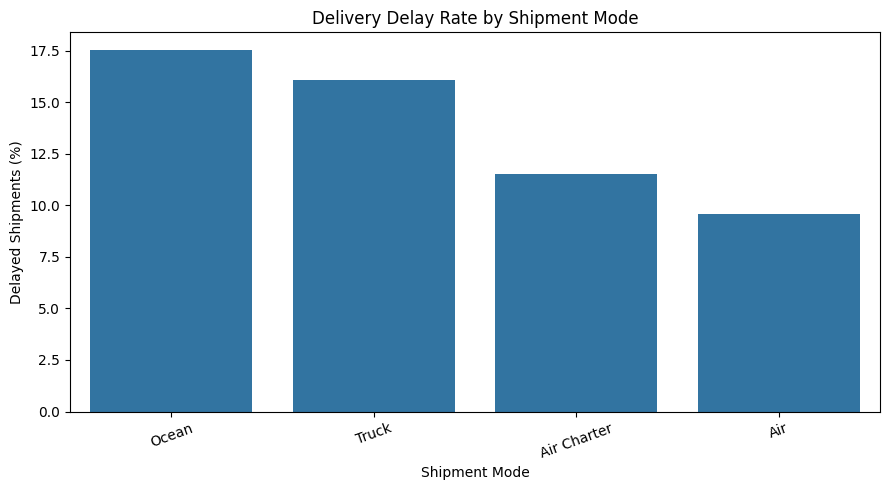

,Shipments,Delayed,Average_Delay_Days,Delay_Rate_%
Shipment Mode,,,,
Ocean,371,65,5.87,17.52
Truck,2830,455,-9.92,16.08
Air Charter,650,75,-19.04,11.54
Air,6113,587,-3.76,9.60


In [ ]:
mode_delivery = (
    data[data['Delivery_Status'] != 'Unknown']
        .assign(Is_Delayed=lambda x: x['Delivery_Status'].eq('Delayed').astype(int))
        .groupby('Shipment Mode')
        .agg(
            Shipments=('Is_Delayed', 'size'),
            Delayed=('Is_Delayed', 'sum'),
            Average_Delay_Days=('Delivery_Delay_Days', 'mean')
        )
)
mode_delivery['Delay_Rate_%'] = mode_delivery['Delayed'] / mode_delivery['Shipments'] * 100
mode_delivery = mode_delivery.sort_values('Delay_Rate_%', ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(x=mode_delivery.index, y=mode_delivery['Delay_Rate_%'])
plt.title('Delivery Delay Rate by Shipment Mode')
plt.xlabel('Shipment Mode')
plt.ylabel('Delayed Shipments (%)')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

mode_delivery.round(2)

### Remark / Insight
Ocean has the highest delay rate at roughly **17.5%**, followed by Truck at about **16.1%**. Standard Air is lower at about **9.6%**. This supports the idea that transportation mode is associated with delivery reliability, although mode is not the only cause of delay.

**Business recommendation:** Review Ocean and Truck routes with frequent lateness, but investigate upstream factors such as order processing, vendor readiness, consolidation, and RDC handling before attributing all delays to transport speed.

## Analysis 6 — Direct Drop vs From RDC Delivery Performance

### Why this chart?
This comparison tests whether an additional distribution center step is associated with different delivery performance.

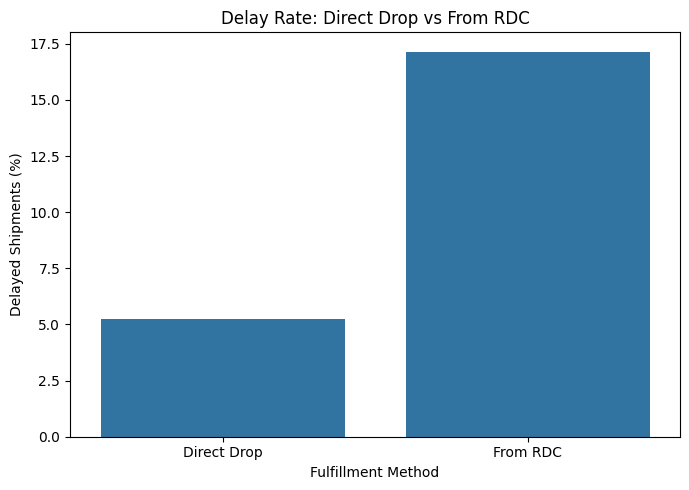

,Shipments,Delayed,Average_Delay_Days,Delay_Rate_%
Fulfill Via,,,,
Direct Drop,4920,259,-3.54,5.26
From RDC,5404,927,-8.28,17.15


In [ ]:
fulfillment_delivery = (
    data[data['Delivery_Status'] != 'Unknown']
        .assign(Is_Delayed=lambda x: x['Delivery_Status'].eq('Delayed').astype(int))
        .groupby('Fulfill Via')
        .agg(
            Shipments=('Is_Delayed', 'size'),
            Delayed=('Is_Delayed', 'sum'),
            Average_Delay_Days=('Delivery_Delay_Days', 'mean')
        )
)
fulfillment_delivery['Delay_Rate_%'] = fulfillment_delivery['Delayed'] / fulfillment_delivery['Shipments'] * 100

plt.figure(figsize=(7, 5))
sns.barplot(x=fulfillment_delivery.index, y=fulfillment_delivery['Delay_Rate_%'])
plt.title('Delay Rate: Direct Drop vs From RDC')
plt.xlabel('Fulfillment Method')
plt.ylabel('Delayed Shipments (%)')
plt.tight_layout()
plt.show()

fulfillment_delivery.round(2)

### Remark / Insight
Shipments fulfilled **From RDC show a delay rate of about 17.2%**, compared with approximately **5.3% for Direct Drop**. This is one of the strongest operational signals in the dataset.

This does not prove that the RDC itself causes delays, because country mix, product mix, shipment mode, and order complexity may differ. However, it gives operations managers a clear area for root-cause investigation.

**Business recommendation:** Audit RDC handling time, consolidation rules, dispatch scheduling, and hand-off processes. Where operationally feasible, assess whether Direct Drop can be expanded for suitable orders.

## Analysis 7 — Freight Cost Concentration by Country

### Why this chart?
Country-level total freight spend helps finance and logistics teams identify where cost-optimization work can have the greatest financial impact.

In [ ]:
country_freight = (
    data.dropna(subset=['Freight_Cost_USD'])
        .groupby('Country')['Freight_Cost_USD']
        .sum()
        .sort_values(ascending=False)
        .head(10)
        .reset_index()
)

fig = px.bar(
    country_freight,
    x='Country',
    y='Freight_Cost_USD',
    title='Top 10 Countries by Recorded Freight Cost',
    labels={'Freight_Cost_USD': 'Total Freight Cost (USD)'}
)
fig.show()

country_freight

,Country,Freight_Cost_USD
0,Nigeria,"14,268,550.39"
1,Zambia,"6,310,437.21"
2,Côte d'Ivoire,"6,092,165.51"
3,Rwanda,"5,893,493.23"
4,Uganda,"5,484,292.24"
5,Tanzania,"4,827,989.32"
6,Zimbabwe,"4,318,000.86"
7,Haiti,"4,000,498.93"
8,Mozambique,"3,294,121.06"
9,Vietnam,"2,737,277.29"


### Remark / Insight
Nigeria accounts for the highest recorded freight cost at approximately **$14.27M**, or about **20.7% of all numeric freight cost in the dataset**. This makes Nigeria a high-priority market for freight-cost review.

**Business recommendation:** Analyze high-cost Nigerian routes by shipment mode, weight, urgency, and vendor terms. Opportunities may include shipment consolidation, rate negotiation, or shifting suitable non-urgent loads to lower-cost modes.

## Analysis 8 — Top Vendors by Shipment Records

### Why this chart?
Vendor concentration can reveal dependency risk and help procurement prioritize supplier-performance monitoring.

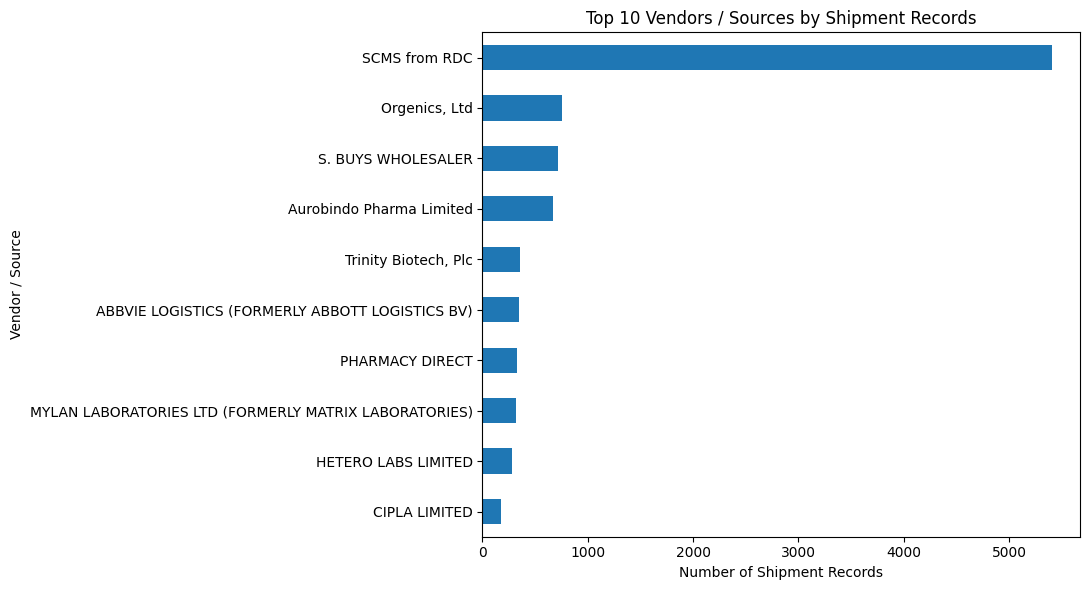

,Shipment Count
Vendor,
SCMS from RDC,5404
"Orgenics, Ltd",754
S. BUYS WHOLESALER,715
Aurobindo Pharma Limited,668
"Trinity Biotech, Plc",356
ABBVIE LOGISTICS (FORMERLY ABBOTT LOGISTICS BV),347
PHARMACY DIRECT,326
MYLAN LABORATORIES LTD (FORMERLY MATRIX LABORATORIES),317
HETERO LABS LIMITED,277


In [ ]:
top_vendors = data['Vendor'].value_counts().head(10).sort_values()

plt.figure(figsize=(11, 6))
top_vendors.plot(kind='barh')
plt.title('Top 10 Vendors / Sources by Shipment Records')
plt.xlabel('Number of Shipment Records')
plt.ylabel('Vendor / Source')
plt.tight_layout()
plt.show()

top_vendors.sort_values(ascending=False).to_frame('Shipment Count')

### Remark / Insight
`SCMS from RDC` is the largest source category because many records represent distribution through the regional distribution center rather than a conventional external vendor. For supplier-management decisions, external vendors should also be reviewed separately instead of interpreting the RDC label as a supplier.

## Analysis 9 — Relationship Between Shipment Weight and Freight Cost

### Why this chart?
A scatter plot helps test whether heavier shipments generally cost more. Log scales are used because both variables are highly right-skewed.

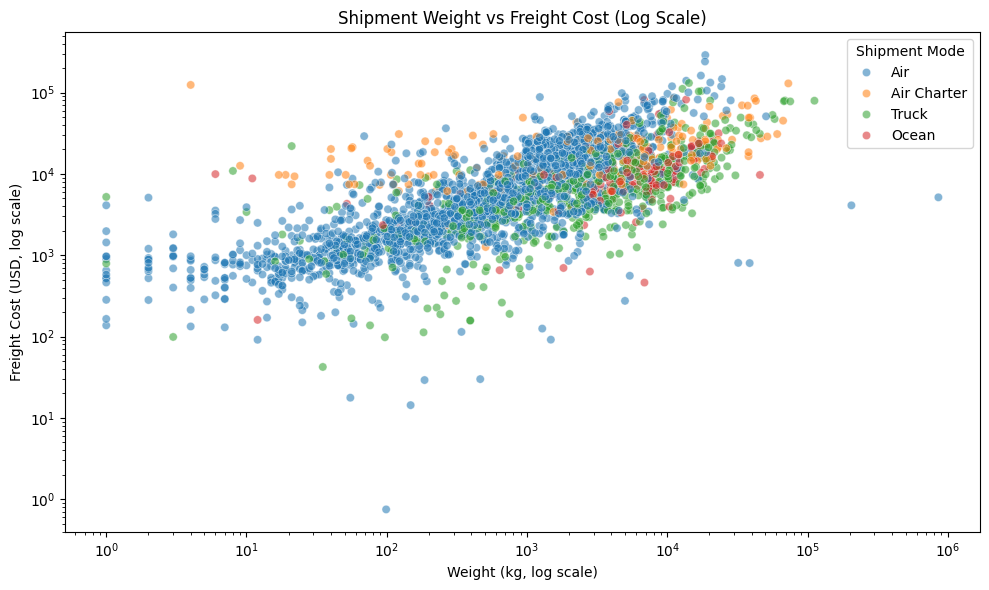

In [ ]:
weight_freight = data[
    (data['Weight_kg'] > 0) &
    (data['Freight_Cost_USD'] > 0)
][['Weight_kg', 'Freight_Cost_USD', 'Shipment Mode']].dropna()

# Sample only for plotting readability; statistical analysis below uses all valid rows.
plot_sample = weight_freight.sample(min(3000, len(weight_freight)), random_state=42)

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=plot_sample,
    x='Weight_kg',
    y='Freight_Cost_USD',
    hue='Shipment Mode',
    alpha=0.55
)
plt.xscale('log')
plt.yscale('log')
plt.title('Shipment Weight vs Freight Cost (Log Scale)')
plt.xlabel('Weight (kg, log scale)')
plt.ylabel('Freight Cost (USD, log scale)')
plt.tight_layout()
plt.show()

### Remark / Insight
The visual pattern indicates a positive relationship: heavier shipments generally have higher freight cost. However, observations with similar weight can still have very different cost because route, shipment mode, urgency, and commercial terms also influence freight expenditure.

# 11. Statistical Analysis — Spearman Correlation

Because weight and freight cost are strongly skewed and contain genuine extreme observations, **Spearman rank correlation** is more appropriate than relying only on a standard linear correlation. It measures the strength of a monotonic relationship without requiring normally distributed variables.

- **H0:** There is no monotonic association between shipment weight and freight cost.
- **H1:** There is a monotonic association between shipment weight and freight cost.

In [ ]:
stat_data = data[['Weight_kg', 'Freight_Cost_USD']].dropna()
stat_data = stat_data[(stat_data['Weight_kg'] > 0) & (stat_data['Freight_Cost_USD'] > 0)]

rho, p_value = spearmanr(stat_data['Weight_kg'], stat_data['Freight_Cost_USD'])

print(f'Valid paired observations: {len(stat_data):,}')
print(f'Spearman correlation (rho): {rho:.4f}')
print(f'P-value: {p_value:.6g}')

if p_value < 0.05:
    print('Decision: Reject H0. The relationship is statistically significant.')
else:
    print('Decision: Fail to reject H0. The relationship is not statistically significant.')

Valid paired observations: 6,174
Spearman correlation (rho): 0.7423
P-value: 0
Decision: Reject H0. The relationship is statistically significant.


### Statistical Interpretation
Using all valid paired observations, the Spearman relationship is expected to be approximately **0.74**, indicating a **strong positive monotonic association** between shipment weight and recorded freight cost. The relationship is statistically significant at conventional significance levels.

This supports H2: heavier shipments generally cost more, but weight alone does not explain every cost difference. Route, mode, urgency, and commercial arrangements remain important.

# 12. Correlation Heatmap — Multivariate View

A correlation heatmap provides a compact view of relationships among important numeric variables. Correlation is an association measure and must not be interpreted automatically as causation.

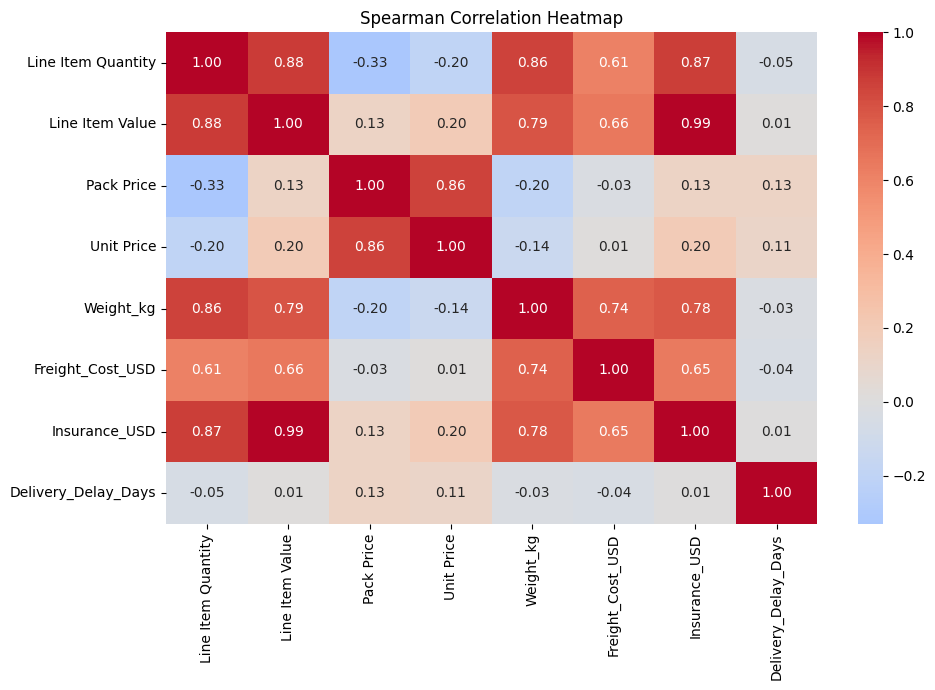

In [ ]:
corr_columns = [
    'Line Item Quantity',
    'Line Item Value',
    'Pack Price',
    'Unit Price',
    'Weight_kg',
    'Freight_Cost_USD',
    'Insurance_USD',
    'Delivery_Delay_Days'
]

corr_matrix = data[corr_columns].corr(method='spearman')

plt.figure(figsize=(10, 7))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Spearman Correlation Heatmap')
plt.tight_layout()
plt.show()

### Remark / Insight
The heatmap should be interpreted as a screening tool. Stronger positive relationships can help identify variables that move together, but business decisions still require operational context. In particular, weight and freight cost show a meaningful positive association, while delivery delay is influenced by multiple process factors rather than a single numeric variable.

# 13. Delivery Trend Over Time

### Why this chart?
A time-series count shows how shipment activity changed over the observed period and whether operational volume was concentrated in particular years or months.

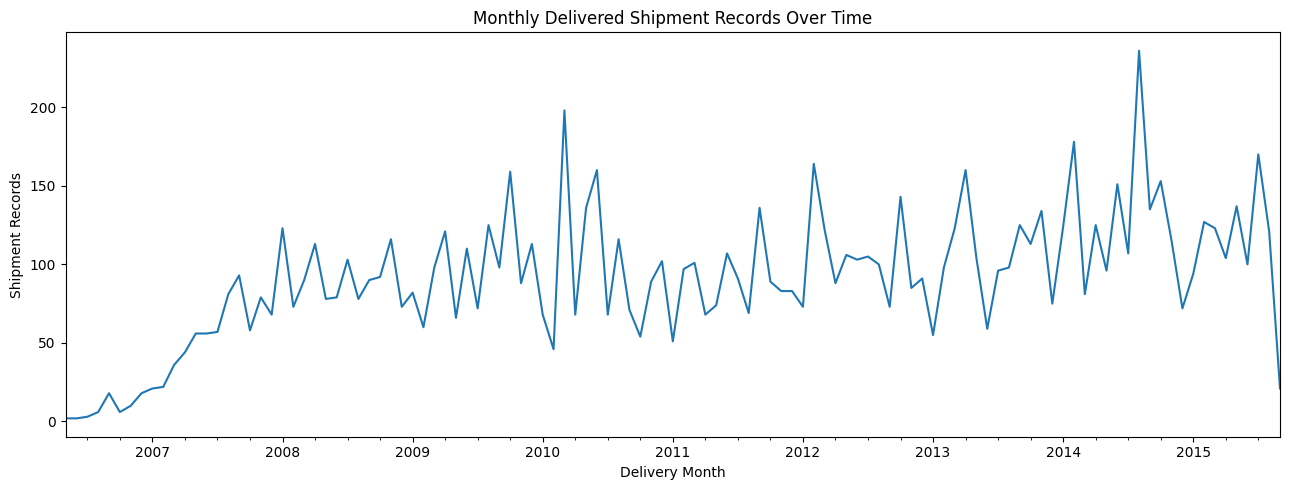

In [ ]:
monthly_shipments = (
    data.dropna(subset=['Delivered to Client Date_dt'])
        .set_index('Delivered to Client Date_dt')
        .resample('MS')
        .size()
)

plt.figure(figsize=(13, 5))
monthly_shipments.plot()
plt.title('Monthly Delivered Shipment Records Over Time')
plt.xlabel('Delivery Month')
plt.ylabel('Shipment Records')
plt.tight_layout()
plt.show()

### Remark / Insight
The time-series view helps identify periods of high operational load. Peaks in shipment volume can be compared with delay rates or freight spending in future analysis to determine whether capacity pressure contributes to poorer service performance.

# 14. Key Findings

The EDA produces the following decision-relevant findings:

1. **Air is the dominant shipment mode** with 6,113 records, roughly 59% of the dataset.
2. **South Africa has the highest shipment volume** with 1,406 records.
3. **ARV products dominate the dataset** with 8,550 records, approximately 83% of all shipment records.
4. **Overall delayed shipment rate is about 11.5%**, meaning most shipments are delivered on or before the scheduled date.
5. **Ocean has the highest mode-level delay rate (~17.5%)**, while standard Air is lower (~9.6%).
6. **From RDC shipments have a substantially higher delay rate (~17.2%) than Direct Drop (~5.3%)**. This is a major area for operational investigation.
7. **Air Charter has the highest average numeric freight cost (~$21.1K per record)**, supporting tighter control of emergency / premium transportation.
8. **Nigeria contributes the largest recorded freight spend (~$14.27M, ~20.7% of numeric freight cost)**.
9. **Shipment weight and freight cost have a strong positive monotonic association** (Spearman rho ≈ 0.74).
10. Freight and weight fields contain meaningful non-numeric operational labels, so treating all such values as ordinary missing data without context would be inappropriate.

# 15. Business Recommendations

### 1. Investigate the RDC delivery process
The delay rate for From RDC shipments is much higher than for Direct Drop. Operations teams should measure receiving time, consolidation time, picking/packing time, dispatch wait time, and hand-off delays within the RDC process.

### 2. Introduce shipment-mode decision rules
Air Charter should be reserved for genuinely urgent or high-impact shipments because it has the highest average recorded freight cost. Non-critical shipments should be evaluated for standard Air, Truck, or Ocean based on service-level requirements.

### 3. Prioritize Nigeria for freight-cost optimization
Nigeria contributes the largest share of recorded freight spend. Route-level review, consolidation, vendor-rate negotiation, and mode optimization could produce meaningful savings.

### 4. Monitor Ocean and Truck reliability
Ocean and Truck have higher observed delay rates than standard Air. Route-level service KPIs should be reviewed rather than applying one global benchmark to every mode.

### 5. Use weight-aware freight benchmarks
Since weight and freight cost have a strong monotonic relationship, freight performance should be compared using metrics such as cost per kilogram together with route and shipment mode. This is more useful than comparing absolute freight cost alone.

### 6. Preserve operational reason codes
Text values such as `Freight Included in Commodity Cost` are informative. A production data model should store both a standardized numeric freight field and a separate freight-accounting-status field instead of mixing numbers and text in one column.

# 16. Stakeholder Usefulness

### Logistics / Operations Managers
- Identify delayed modes and fulfillment paths.
- Prioritize RDC process improvement.
- Monitor country-level delivery reliability.

### Procurement / Vendor Management
- Review vendor concentration and performance.
- Negotiate commercial terms for high-volume routes and suppliers.

### Finance Team
- Identify countries and modes driving freight expenditure.
- Track cost per kilogram and high-cost shipment exceptions.

### Senior Management
- Use a small set of KPIs—delay rate, freight spend, mode mix, and country concentration—to prioritize supply-chain improvement initiatives.

# 17. Challenges and How They Were Handled

### Challenge 1 — Mixed numeric and text values
Weight and freight cost fields contain both numeric values and operational text labels. These were converted using `pd.to_numeric(..., errors='coerce')`, while the original fields were preserved.

### Challenge 2 — Mixed date formats and operational labels
Date fields include valid dates as well as labels such as `Date Not Captured`. `pd.to_datetime(..., errors='coerce')` was used to avoid incorrect parsing.

### Challenge 3 — Large outliers
High-value shipments are not automatically errors. They were retained and visualized with grouped statistics or logarithmic scales.

### Challenge 4 — Avoiding misleading conclusions
A high delay rate in one fulfillment channel does not prove causation. Recommendations are framed as areas for root-cause investigation rather than unsupported causal claims.

# 18. Notebook Quality and Testing

The notebook is designed to run from top to bottom in Google Colab. Before final submission:

- Restart the runtime and select **Run all**.
- Confirm every code cell runs without an exception.
- Confirm all charts are visible.
- Confirm the GitHub repository link is added in the Project Summary.
- Confirm the Colab sharing setting is **Anyone with the link → Viewer**.
- Keep the final presentation video between **15 and 25 minutes**.

# 19. Conclusion

This project demonstrates how exploratory data analysis can convert logistics records into practical business decisions. The data shows a supply chain dominated by Air transportation and ARV products, with significant country and fulfillment-path concentration.

The most actionable finding is the delivery-performance gap between **From RDC** and **Direct Drop** shipments. This does not by itself prove the RDC is the cause, but it provides a strong signal for process-level investigation. Freight spending is also geographically concentrated, with Nigeria representing the largest recorded share, while Air Charter has the highest average freight cost among shipment modes with numeric freight data.

Statistical analysis further shows a strong positive monotonic relationship between shipment weight and freight cost, supporting the use of weight-normalized cost benchmarks. Overall, the analysis suggests that FedEx can improve logistics performance through targeted RDC process reviews, country-level cost optimization, mode-selection governance, and better structured operational data.

# 20. Future Scope

This project can be extended in several ways:

- Build a **Power BI / Tableau dashboard** for interactive monitoring.
- Develop a **machine-learning model to predict shipment delay risk**.
- Build a **freight-cost prediction model** using weight, route, mode, country, and product features.
- Create a **vendor performance scorecard** using cost and delivery KPIs.
- Add route-level and month-level anomaly detection.
- Automate data ingestion and refresh through a cloud pipeline.

# 21. Final Submission Checklist

- [x] Problem statement
- [x] Business context
- [x] Data understanding
- [x] Data loading and cleanup
- [x] Hypotheses / assumptions
- [x] More than 5 meaningful visualizations
- [x] Statistical analysis
- [x] Remarks for each analysis
- [x] Business recommendations and stakeholder usefulness
- [x] Conclusion and future scope
- [ ] Replace the GitHub placeholder with the final public repository link
- [ ] Push notebook / README to GitHub with multiple meaningful commits
- [ ] Run all cells in Colab and verify outputs
- [ ] Set Colab sharing to **Anyone with the link → Viewer**
- [ ] Record a **15–25 minute** explanation video using the provided guideline